In [6]:
import numpy as np
import matplotlib.pyplot as plt

### Question 1a: Pressure as a function of height

In [64]:
N = 1000
Z_start = 0
Z_end = 10000
p_z = np.zeros([N])
p_0 = 1.018*10**5
T_sfc = 293
gamma = -6 / 1000
Rd = 287.0
g = 9.81

z = np.linspace(Z_start, Z_end, N)

def Temperature_z(T_sfc, gamma, z):
    return T_sfc + gamma*z

def Pressure_analytic(p_0, T_sfc, gamma, z, Rd, g):
    T = Temperature_z(T_sfc, gamma, z)

    exponent = -g/(Rd*gamma)
    return p_0 * (T/T_sfc)**exponent

def Pressure_numerical(p_0, z, Rd, g):
    T = Temperature_z(T_sfc, gamma, z)
    p = np.zeros_like(z)
    p[0] = p_0

    for i in range(len(z)-1):
        dz = z[i+1] - z[i]
        T_mid = 0.5*(T[i] + T[i+1])
        p[i+1] = p[i] * np.exp(-g*dz/(Rd*T_mid))

    return p

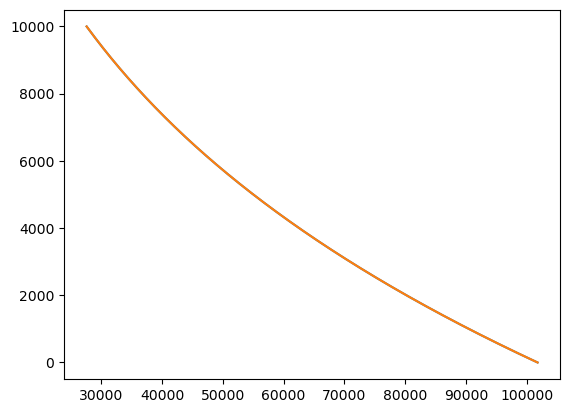

In [65]:
# Results are the same (very small difference)
p_z_num = Pressure_numerical(p_0, z, Rd, g)
p_z_anal = Pressure_analytic(p_0, T_sfc, gamma, z, Rd, g)
plt.plot(p_z_num, z)
plt.plot(p_z_anal, z)

### Question 1b: Vertical profile of air density

In [66]:
def air_density_z(Rd, T_sfc,gamma, z, p_0, g):
    T = Temperature_z(T_sfc, gamma, z)
    p = Pressure_numerical(p_0, z, Rd, g)
    rho = np.zeros(len(T))
    for i in range(len(T)):
        rho[i] = p[i] / (Rd * T[i])
    return rho

6696.696696696697


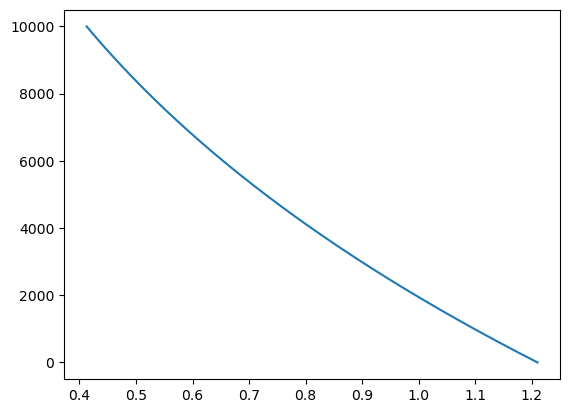

In [71]:
rho = air_density_z(Rd, T_sfc, gamma, z, p_0, g)
 
boundary = 0.5 * rho[0]
z_half = z[np.argmin(np.abs(rho - boundary))]
print(z_half)

plt.plot(rho, z)

## Question 1c: Vertical profiles of water vapor specific humidity

In [ ]:
RH = 0.8
T_scf_new = [271, 303]
Rv = 461.5

def e_sat(T_sfc,gamma, z):
    T = Temperature_z(T_sfc, gamma, z)
    esat = np.zeros(len(T))
    for i in range(len(T)):
        esat[i] = 610.78*np.exp(17.2694 * (T[i] -273.16) / (T[i] - 35.86))
    return esat

def vapor_pressure(RH, z, T_sfc):
    esat = e_sat(T_sfc,gamma, z)
    e_v = np.zeros(len(esat))

    for i in range(len(esat)):
        e_v[i] = RH * esat[i]

    return e_v

#def q_sat(Rd, Rv, p_0, z, T_sfc, g): # Not needed
#    esat = e_sat(T_sfc,gamma, z)
#    p = Pressure_numerical(p_0, z, Rd, g)
#   qst = np.zeros(len(esat))
#
#    for i in range(len(esat)):
#        qst[i] = Rd / Rv * esat[i]/p[i]
#    return qst

def q_v(Rd, Rv, p_0, z, T_sfc, g, RH):
    e_v = vapor_pressure(RH, z, T_sfc)
    p = Pressure_numerical(p_0, z, Rd, g)

    q_vs = np.zeros(len(e_v))
    
    for i in range(len(e_v)):
        rv = e_v[i] * Rd / (Rv * p[i])
        q_vs[i] = rv / (1+ rv)

    return q_vs

0.00036917439371386186 0.005437849463497625


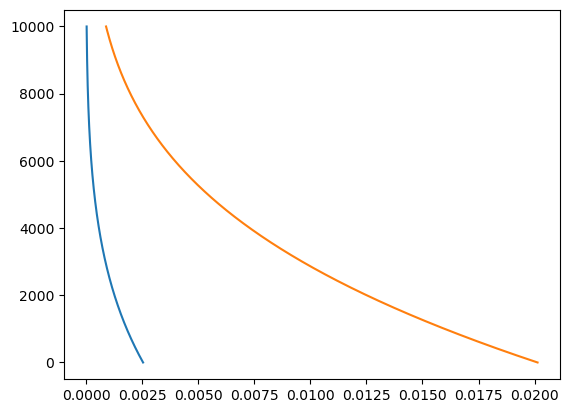

In [109]:
q_v1 = q_v(Rd, Rv, p_0, z, T_scf_new[0], g, RH)
q_v2 = q_v(Rd, Rv, p_0, z, T_scf_new[1], g, RH)

plt.plot(q_v1, z)
plt.plot(q_v2, z)

# VALUES Z= 5K
z_int = 5000
q1_5000 = q_v1[np.argmin(np.abs(z - z_int))]
q2_5000 = q_v2[np.argmin(np.abs(z - z_int))]
print(q1_5000, q2_5000 )

## Question 1d: Water Vapor Path

In [121]:
def WVP(Rd, Rv, T_sfc, gamma, z, p_0, g, RH):
    rho = air_density_z(Rd, T_sfc, gamma, z, p_0, g)
    q_vs = q_v(Rd, Rv, p_0, z, T_sfc, g, RH)
    
    WVP_value = np.trapz(rho * q_vs, z)
    
    return WVP_value

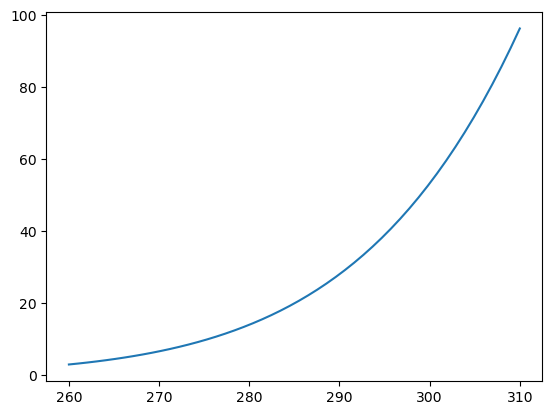

2.844396675972211 96.28912651355704


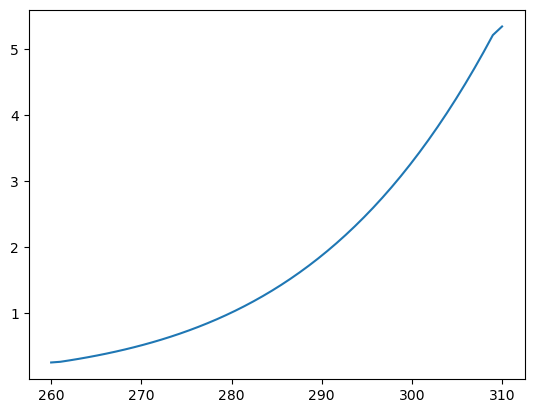

In [132]:
T_sfcs = np.linspace(260,310,50)

WVP_values = np.zeros(len(T_sfcs))

for i in range(len(T_sfcs)):
    WVP_values[i] = WVP(Rd,Rv, T_sfcs[i], gamma, z, p_0,g, RH)

plt.plot(T_sfcs, WVP_values)
plt.show()

min_WVP = np.min(WVP_values)
max_WVP = np.max(WVP_values)

dWVP_dTsfc = np.gradient(WVP_values, T_sfcs)

print(min_WVP, max_WVP)

plt.plot(T_sfcs, dWVP_dTsfc)

## Question 1e: Rainfall Rate P in mm/h as a function of surface Temperature

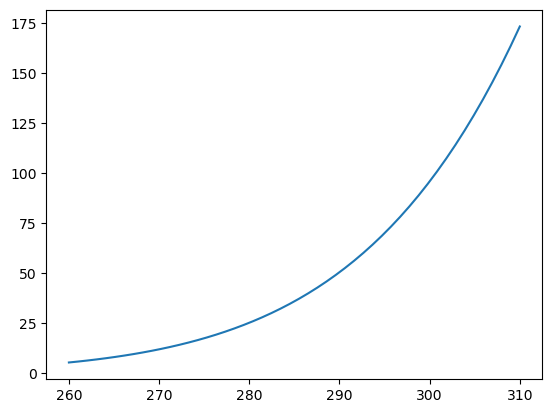

In [ ]:
H = 10000 # height
W = 5 # m/s
velocity = 3600 * W # m / hr

P_mm_per_h = WVP_values * velocity / 10000

# 175 mm/h seems a bit intense, even for hot climates
# precipitation at -13 is also interesting
# Other values seem reasonable enough though

plt.plot(T_sfcs, P_mm_per_h)